

# Clustering



**Clustering** é uma técnica de aprendizado de máquina **não supervisionado** que tem como objetivo agrupar um conjunto de objetos de tal forma que os objetos no mesmo grupo (ou cluster) sejam mais semelhantes entre si do que com os objetos de outros grupos.

Existem diversos algoritmos de clustering, cada um com suas próprias características e aplicações. Alguns dos algoritmos mais comuns incluem:

- **K-Means**: Um dos algoritmos de clustering mais populares, que particiona os dados em K clusters, onde cada cluster é representado pela média dos pontos dentro dele.
- **Hierarchical Clustering**: Cria uma hierarquia de clusters, que pode ser representada como uma árvore (dendrograma). Pode ser aglomerativo (bottom-up) ou divisivo (top-down).
- **DBSCAN**: Um algoritmo de clustering baseado em densidade que é capaz de encontrar clusters de forma arbitrária e lidar com ruídos.

O clustering é amplamente utilizado em diversas áreas, como segmentação de clientes, análise de redes sociais, reconhecimento de padrões e muito mais. Ele é especialmente útil quando não se tem rótulos ou categorias pré-definidas para os dados, permitindo que os próprios dados revelem suas estruturas subjacentes.

## K-Means

O algoritmo K-Means é um método de clustering que particiona os dados em $K$ clusters, onde cada cluster é representado pela média dos pontos dentro dele (**centroide**).

O algoritmo atribui cada ponto de dados ao cluster mais próximo com base em uma métrica de distância, geralmente a distância euclidiana. O objetivo do K-means é minimizar a soma dos quadrados das distâncias entre os pontos de dados e seus respectivos centroides, o que é conhecido como **within-cluster sum of squares (WCSS)**. Essa técnica é amplamente utilizada em análise de dados, reconhecimento de padrões e processamento de imagens devido à sua simplicidade e eficiência.

![](https://github.com/hsandmann/biblio/blob/main/ml/aula07/kmeans-illustration.png?raw=true)

### Conceitos-chave

- **Clusters**: Grupos de pontos de dados que são semelhantes entre si com base em uma métrica de distância.
- **Aprendizado Não Supervisionado**: O algoritmo funciona sem dados rotulados, identificando padrões apenas com base na estrutura dos dados.
- **Centroides**: São os "centros" dos clusters, representados pela média de todos os pontos em um cluster.
- **K**: O número de clusters, que deve ser especificado antecipadamente (por exemplo, K=3 significa dividir os dados em 3 clusters).
- **Métrica de Distância**: Normalmente, a distância euclidiana é usada para medir quão distante um ponto de dados está de um centróide. O objetivo é atribuir pontos ao centróide mais próximo.
- **Objetivo**: Minimizar a soma dos quadrados das distâncias dentro do cluster (WCSS - Within-Cluster Sum of Squares), que é a soma das distâncias ao quadrado entre cada ponto e seu centróide atribuído. Matematicamente, para um conjunto de dados e centróides, o objetivo é minimizar a função de custo. Exemplo, para o dataset $\textbf{X} = \{x_1, x_2, \dots, x_n\}$ e centroides $\mu=\{ \mu_1, \mu_2, \dots, \mu_n \}$, a função custo é:

    $$ \textbf{WCSS} = \arg \min_{\mu} \sum_{i=1}^{K} \sum_{x \in C_i} ||x - \mu_i||^2 $$

    onde $C_i$ é o conjunto de pontos no cluster $i$ e $\mu_i$ é o centróide do cluster $i$.

> K-Means assume que os clusters são esféricos e de tamanho semelhante, o que pode não ser adequado para todos os conjuntos de dados. Além disso, o algoritmo pode ser sensível a outliers e à escolha inicial dos centroides, o que pode levar a resultados subótimos. Para mitigar esses problemas, é comum executar o K-means várias vezes com o mesmo número de $k$ mas com diferentes inicializações e escolher a melhor solução com base na menor WCSS.

### Passo a passo

1. **Inicialização**:

    - Escolha o valor de $K$;
    
    - Aleatoriamento selecione o $K$ inicial do dataset.


2. **Atribuição**:

    - Para cada ponto do dataset, calcule a distância para todos os $k$-centroides;
    
    - Atribua o ponto ao cluster com o centróide mais próximo, com base na métrica de distância escolhida (geralmente a distância euclidiana).


3. **Atualização**:

    - Para cada cluster, recalcule os centroides dos clusters com base nos pontos atribuídos a cada cluster;
    
    - O novo centróide é a média dos pontos de dados em cada cluster.


4. **Iteração**:
    
    - Repita os passos de atribuição (passo 2) e atualização até atingir um dos critérios de parada:
    
        - os centroides não mudem mais (ou a mudança é menor que um limiar - threshold, e.g., 0.001);

        - até atingir um número máximo de iterações (para evitar loops infinitos);
        
        - quando o WCSS cai minimamento entre as iterações.


5. **Saída**:

    - As centroides definidas;

    - As atribuições de cluster para ponto do dataset.

### Exemplo Numérico

Dado um dataset de 2-dimensões (2-features), com 5 exemplos:

$$
\begin{bmatrix}
1 & 2 \\
2 & 1 \\
5 & 8 \\
6 & 7 \\
8 & 6
\end{bmatrix}
$$

Vamos assumir $k = 2$.

- **Inicialização**: aleatoriamente escolhemos os centroides, e.g.: $C_1=(1, 2)$ e $C_2=(5,8)$.

- **Atribuição**:

    - $(1, 2)$ e $(2, 1)$ estão mais próximos de $C_1$ $\implies$ Cluster 1.

    - $(5, 8)$, $(6, 7)$ e $(8, 6)$ estão mais próximos de $C_2$ $\implies$ Cluster 2.

- **Atualização**:

    - $C_1$ = média entre $(1, 2)$ e $(2, 1)$ = $(1.5, 1.5)$;

    - $C_e$ = média entre $(5, 8)$, $(6, 7)$ e $(8, 6)$ = $(6.33, 7)$.

- **Iteração**:

    - Reatribuir os pontos aos novos centroides;

    - Repita os passos de 2 e 3 até uma estabilização.

Para o exemplo, após a convergência, teremos dois clusters, com centroides em $(1.5, 1.5)$ e $(6.33, 7)$.

### Exemplo Ilustrativo

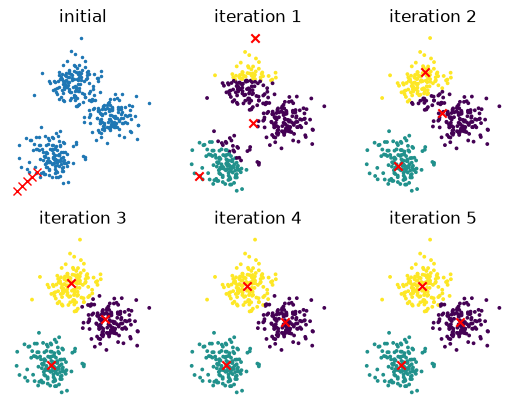

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

fig, axs = plt.subplots(2, 3)

ax = axs[0, 0]
ax.set_title("initial")

X, _ = make_blobs(n_samples=400, centers=3, n_features=2, random_state=42, cluster_std=2.5)
ax.plot(X[:, 0], X[:, 1], '.', ms=3)

initial_centers = np.array([[-10, -10], [-11, -11], [-12, -12], [-13, -13], [-14, -14]])
ax.plot(initial_centers[:, 0], initial_centers[:, 1], 'xr')
ax.axis('off')

max_it = 5
k = 3
for it in range(1, max_it + 1):
    kmeans = KMeans(
        k,
        n_init=1,
        random_state=42,
        init=initial_centers[:k],
        max_iter=it
    ).fit(X)
    y = kmeans.labels_
    ax = axs[int(it/3), it%3]
    ax.set_title(f'iteration {it}')
    ax.axis('off')
    ax.scatter(X[:, 0], X[:, 1], c=y, s=k)
    ax.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], c="red", marker='x')

# k = 10
# inertias = [KMeans(k, n_init=1, random_state=42).fit(X).inertia_ for k in range(1,k+1)]

plt.show()
# inertias

### Vantagens e Desvantagens

| Aspecto | Vantagens | Desvantagens |
|---|---|---|
| **Simplicidade** | Fácil de entender e implementar; computacionalmente eficiente ($O(n)$ por iteração). | Sensível ao centróide inicial; pode converter para um *ótimo-local*. |
| **Escalabilidade** | Funciona bem com datasets grandes, apresenta complexidade de tempo linear. | Assume que os clusters são esféricos; tem dificuldades com densidades não convexas ou variáveis. |
| **Saída** | Produz agrupamentos compactos e densos; centroides interpretáveis. | Requer um valor K predefinido; valores discrepantes podem distorcer os resultados. |

### Escolhendo $K$

#### **Método do cotovelo** (Elbow Method):

Plote WCSS vs. $K$ e procure por um **cotovelo** onde a taxa de decaimento caí devagar.

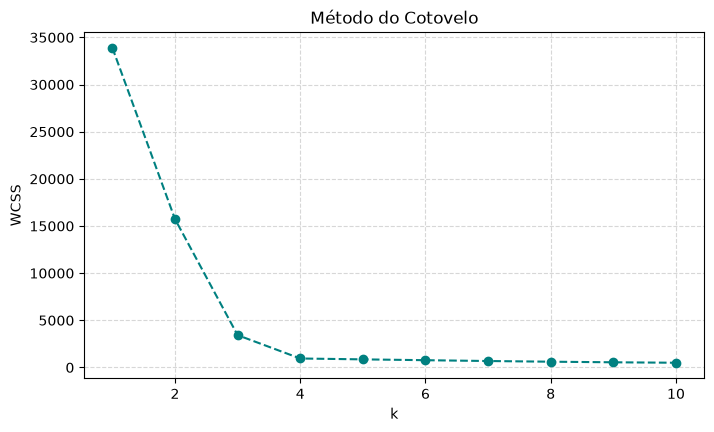

In [2]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

X, _ = make_blobs(n_samples=500, centers=4, random_state=42)
inertias = [KMeans(k, n_init=10, random_state=42).fit(X).inertia_ for k in range(1,11)]

plt.figure(figsize=(8,4.5))
plt.plot(range(1,11), inertias, 'o--', color='teal')
plt.xlabel('k')
plt.ylabel('WCSS')
plt.title('Método do Cotovelo')
plt.grid(True, ls='--', alpha=0.5)
plt.show()

#### **Método da Silhueta** (Silhouette Score):

A silhueta mede quão bem cada exemplo está agrupado em relação aos outros clusters.

Ela combina duas ideias:

- **a** = quão próximo o exemplo está dos outros exemplos do mesmo cluster (quanto menor → melhor, cluster compacto);

- **b** = quão distante o exemplo está do cluster mais próximo diferente do seu (quanto maior → melhor, boa separação).

A fórmula do coeficiente de silhueta para um exemplo $i$ é:

$$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$

Intervalo: $−1 \leq s(i) \leq +1$

| score | significado |
|--:|---|
| $\approx +1$ | exemplo muito bem classificado (muito dentro do seu cluster e longe dos outros) |
| $\approx 0$ | exemplo na fronteira entre dois clusters |
| $ < 0$ | exemplo provavelmente está no cluster errado |



##### **Passo a passo**

Para cada exemplo $i$ no dataset:

- a. Calcule $a(i)$: distância média entre o exemplo $i$ e todos os outros exemplos do mesmo cluster:

    $a(i) = \displaystyle \frac{1}{|C_i| - 1} \sum_{j \in C_i, j \neq i} d(i,j)$

    (onde $C_i$ é número de exemplos do cluster que contém o exemplo $i$, $d$ é a distância — normalmente Euclidiana)
    
- b. Calcule $b(i)$: distância média entre o exemplo $i$ e todos os exemplos do cluster mais próximo diferente do seu.

    Para cada cluster diferente de $C_i$:

    - calcule a distância média de $i$ para todos os pontos daquele cluster;

    - pegue o menor desses valores médios → esse é $b(i)$

        $b(i) = \displaystyle \min_{C_k \neq C_i} \left( \frac{1}{|C_k|} \sum_{j \in C_k} d(i,j) \right)$

Calcule $s(i)$ para cada ponto:

$$s(i) =
\begin{cases}
1 - \frac{a(i)}{b(i)} & \text{se } a(i) < b(i) \\
0 & \text{se } a(i) = b(i) \\
\frac{b(i)}{a(i)} - 1 & \text{se } a(i) > b(i)
\end{cases}$$

Ou, de forma equivalente e mais usada na prática:$$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$
Silhouette Score médio do modelo (o valor que plotamos no método da silhueta):

$$S = \frac{1}{N} \sum_{i=1}^N s(i)$$

onde $N$ é o número total de exemplos.


##### **Resultado**

| Situação | Interpretação da Silhueta média | Ação sugerida |
|--:|---|---|
| $> 0.7$ | Estrutura muito forte | Excelente agrupamento |
| $(0.5; 0.7]$ | Estrutura razoável | Bom agrupamento |
| $(0.25; 0.5]$ | Estrutura fraca | Talvez aceitável |
| $[0; 0.25]$ | Sem estrutura significativa | Talvez K-Means não seja adequado |
| $<0$ | Muitos pontos mal classificados | Tente outro $k$ ou outro algoritmo |

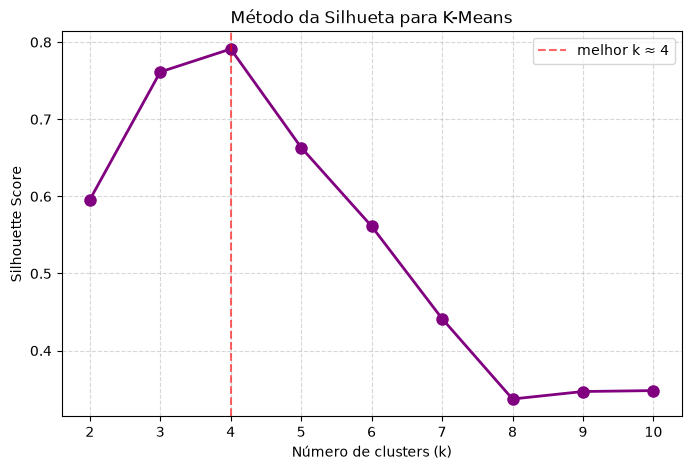

In [3]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score

X, _ = make_blobs(n_samples=500, centers=4, random_state=42)

scores = [silhouette_score(X, KMeans(k, n_init=10, random_state=42).fit_predict(X))
          for k in range(2, 11)]

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), scores, 'o-', color='purple', linewidth=2, markersize=8)
plt.xlabel('Número de clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Método da Silhueta para K-Means')
plt.grid(True, ls='--', alpha=0.5)
plt.axvline(x=4, color='red', linestyle='--', alpha=0.6, label='melhor k ≈ 4')
plt.legend()
plt.show()

#### **Comparação**

|Critério|Método do Cotovelo (Elbow)|Método da Silhueta (Silhouette)|Vencedor (na maioria dos casos)|
|---|---|---|---|
| O que mede|Redução da inércia (soma dos quadrados intra-cluster – WCSS)|Qualidade da separação e coesão dos clusters (média do coeficiente de silhueta por ponto)|—|
| Intervalo de valores|Inércia: sempre positiva e decrescente|Silhueta média: -1 a +1|—|
| Facilidade de interpretação| Inspeção visual (procura o "cotovelo")|Mais objetivo: maior valor = melhor k|Silhueta|
| Facilidade de automação|Difícil (o cotovelo nem sempre é claro/obvio)|Fácil (basta pegar o k com maior score)|Silhueta|
| Sensibilidade a ruído / outliers|Moderada (inércia é sensível a pontos distantes)|Alta (pontos mal classificados ou outliers puxam o score para baixo)|Cotovelo (ligeira vantagem)|
| Funciona bem quando clusters têm tamanhos parecidos|Sim|Sim|Empate|
| Funciona bem quando clusters têm tamanhos muito diferentes|Geralmente sim|Pode falhar (clusters pequenos podem ter silhueta baixa mesmo sendo bons)|Cotovelo|
| Funciona bem em clusters com densidades diferentes|Sim|Pode subestimar clusters densos vs. esparsos|Cotovelo|
| Funciona bem em dados de alta dimensionalidade|Razoável|Pode ser enganoso (maldição da dimensionalidade afeta distâncias)|Cotovelo (mais robusto)|
| Custo computacional|Baixo (só calcula inércia)|Médio-alto (precisa calcular distâncias entre todos os pontos e clusters vizinhos)|Cotovelo|
| "Quando o ""melhor k"" é óbvio"|Muito bom (curva clara)|Excelente (score alto e destacado)|Empate|
| Quando não existe cotovelo claro|Fraco (muitas interpretações possíveis)|Melhor (ainda fornece um máximo mensurável)|Silhueta|
| Indica clusters mal formados|Não diretamente|Sim (score médio baixo ou muitos valores negativos)|Silhueta|
| Recomendação geral de uso|"Primeira análise rápida| dados com clusters bem separados e tamanhos semelhantes"|"Análise mais confiável| quando se quer maximizar separação/coesão"|—|

## Exercícios

1. Aplique K-Means ao [Iris Dataset](https://www.kaggle.com/datasets/uciml/iris).

    - Remova os targets;
    - Pré-processe os dados;
    - Obtenha o resultado de clustering e compare com os dados já classificados.

In [4]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

iris = load_iris(as_frame=True)
df = iris.frame
target = df.pop('target')          # remove os rótulos antes de clusterizar

X = StandardScaler().fit_transform(df.values)   # pré-processamento: padronização

km = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X)
labels = km.labels_

print('ARI (clusters vs espécie real):', round(adjusted_rand_score(target, labels), 3))
print('silhouette:', round(silhouette_score(X, labels), 3))
print()
print(pd.crosstab(labels, target, rownames=['cluster'], colnames=['espécie real']))

ARI (clusters vs espécie real): 0.62
silhouette: 0.46

espécie real   0   1   2
cluster                 
0              0  39  14
1             50   0   0
2              0  11  36


**Resposta:** Carreguei o Iris Dataset via `sklearn.datasets.load_iris`, removi a coluna `target` (as 3 espécies: setosa, versicolor, virginica) antes de qualquer clustering, e pré-processei as 4 features numéricas com `StandardScaler` (todas em cm, mas com desvios-padrão diferentes entre si, então padronizar evita que uma feature domine a distância). Com `KMeans(n_clusters=3, n_init=10, random_state=42)`:

- **ARI entre os clusters e a espécie real = 0.620** — concordância forte, mas não perfeita.
- **Silhueta = 0.460** — estrutura razoável (entre 0.25 e 0.5 na régua de interpretação usada no handout acima).
- A tabela de contingência mostra que o cluster 1 captura **100% da setosa (50/50)** sem nenhum erro — essa espécie é linearmente separável das outras duas. Já os clusters 0 e 2 dividem imperfeitamente versicolor e virginica entre si (cluster 0: 39 versicolor + 14 virginica; cluster 2: 11 versicolor + 36 virginica) — são as duas espécies que se sobrepõem no espaço de features, um fato conhecido do Iris Dataset. Isso explica por que o ARI (0.620) não chega a 1: o erro do K-means não é aleatório, está concentrado exatamente na fronteira entre as duas espécies parecidas.

2. Sobre o exercício anterior, varie o número de $K$, no mínimo $K = \{1, 2, \dots, 10 \}$.

    - Usado o método do cotovelo, plote o gráfico da variação da WCSS;

    - Usado o método da silhueta, plote o gráfico da variação da média da silhueta;

    - Analise os dados sem *bias* de conhecimento prévio dos dados.

        WCSS  silhueta
k                     
1   600.0000       NaN
2   222.3617    0.5818
3   139.8205    0.4599
4   114.0925    0.3869
5    90.9275    0.3459
6    81.5444    0.3171
7    72.6311    0.3202
8    62.5406    0.3387
9    55.1195    0.3424
10   47.3910    0.3518


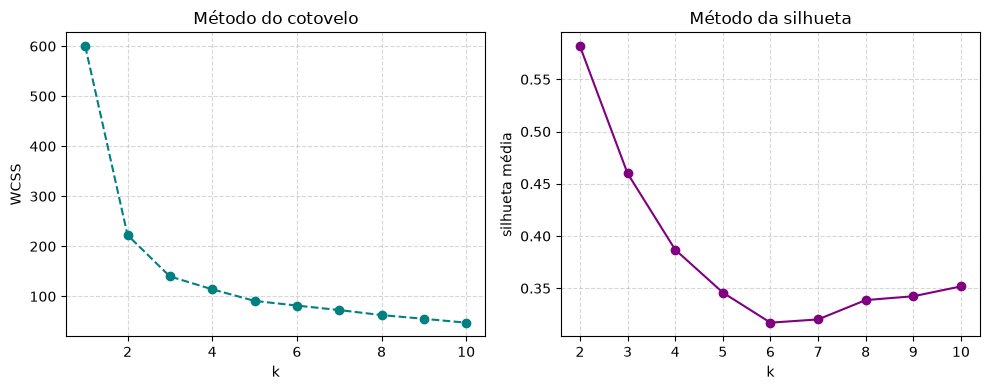

In [5]:
import matplotlib.pyplot as plt

wcss, sils = [], [np.nan]   # silhueta não é definida para k=1
for k in range(1, 11):
    m = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    wcss.append(m.inertia_)
    if k >= 2:
        sils.append(silhouette_score(X, m.labels_))

resumo = pd.DataFrame({'k': range(1, 11), 'WCSS': wcss, 'silhueta': sils}).set_index('k')
print(resumo.round(4))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.plot(resumo.index, resumo['WCSS'], 'o--', color='teal')
ax1.set_xlabel('k'); ax1.set_ylabel('WCSS'); ax1.set_title('Método do cotovelo')
ax1.grid(True, ls='--', alpha=0.5)

ax2.plot(resumo.index[1:], resumo['silhueta'][1:], 'o-', color='purple')
ax2.set_xlabel('k'); ax2.set_ylabel('silhueta média'); ax2.set_title('Método da silhueta')
ax2.grid(True, ls='--', alpha=0.5)
plt.tight_layout(); plt.show()

**Resposta:** Os valores obtidos (k de 1 a 10) foram:

| k | WCSS | silhueta |
|---|---|---|
| 1 | 600.00 | — |
| 2 | 222.36 | 0.5818 |
| 3 | 139.82 | 0.4599 |
| 4 | 114.09 | 0.3869 |
| 5 | 90.93 | 0.3459 |
| 6 | 81.54 | 0.3171 |
| 7 | 72.63 | 0.3202 |
| 8 | 62.54 | 0.3387 |
| 9 | 55.12 | 0.3424 |
| 10 | 47.39 | 0.3518 |

**Análise sem viés (fingindo não saber que existem 3 espécies):** o cotovelo da WCSS é visualmente ambíguo — a queda de k=1→2 (−377.6) e de k=2→3 (−82.5) já são bem menores que a anterior, com uma leve quebra adicional em k=3→4 (−25.7), mas depois de k=4 a curva continua caindo suavemente sem outro ponto óbvio, então o cotovelo por si só sugeriria k=2 **ou** k=3, sem decidir sozinho entre eles. A silhueta, por outro lado, é **máxima em k=2** (0.5818), bem acima de k=3 (0.4599) — ou seja, as duas métricas discordam do valor que sabemos ser o correto (k=3, as 3 espécies).

Isso é coerente com o exercício 1: setosa está isolada, mas versicolor e virginica se sobrepõem bastante no espaço de 4 features — então, geometricamente, **2 grupos bem separados** (setosa vs. {versicolor+virginica}) são mais compactos/coesos do que 3 grupos, mesmo havendo de fato 3 espécies biológicas. Sem o rótulo verdadeiro, um analista guiado só pela silhueta escolheria k=2 e "perderia" a divisão entre versicolor e virginica — o mesmo tipo de armadilha vista no handout (L4, pinguins) e no notebook principal da aula (wine, step 3): índices internos preferem a geometria mais compacta, que nem sempre corresponde à estrutura categórica real.

3. Agora, gerando dados sintéticos $N>=500$, variando $K = \{2, 3, 4, 5, 6, 7\}$, variando as centroides iniciais (no mínimo 3 vezes por configuração), em 2D:

    - aplique K-Means para seguintes configurações de experimentos:

        - 4 classes balanceadas, distribuição em clusters com $\text{std} = 1.2$ (vide [make_blobs](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_blobs.html));

        - 2 classes balanceadas, distribuição em clusters globulares, com $\text{ruído}=0.05$ (vide [make_moons](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_moons.html)).

        - 4 classes balanceadas, distribuição aleatória.

    - comente erros e acertos de cada experimento;

In [6]:
from sklearn.datasets import make_blobs, make_moons
from sklearn.metrics import adjusted_rand_score

rng = np.random.default_rng(7)

# três configurações de dados sintéticos 2D, N = 600 >= 500
X_blobs, y_blobs = make_blobs(n_samples=600, centers=4, cluster_std=1.2, random_state=7)
X_moons, y_moons = make_moons(n_samples=600, noise=0.05, random_state=7)
X_rand = rng.uniform(0, 10, size=(600, 2))   # "distribuição aleatória": ruído uniforme, sem estrutura de grupo real

configuracoes = {
    'blobs (4 classes balanceadas, std=1.2)': (X_blobs, y_blobs),
    'moons (2 classes balanceadas, noise=0.05)': (X_moons, y_moons),
    'aleatório uniforme (sem estrutura real)': (X_rand, None),
}

resultados = []
for nome, (Xc, yc) in configuracoes.items():
    for k in range(2, 8):
        inercias, silhuetas, aris = [], [], []
        for seed in [0, 1, 2]:                      # >= 3 inicializações de centroides por configuração/k
            m = KMeans(n_clusters=k, n_init=1, random_state=seed).fit(Xc)
            inercias.append(m.inertia_)
            silhuetas.append(silhouette_score(Xc, m.labels_))
            if yc is not None:
                aris.append(adjusted_rand_score(yc, m.labels_))
        linha = {'config': nome, 'k': k,
                 'inercia_media': np.mean(inercias), 'inercia_std': np.std(inercias),
                 'silhueta_media': np.mean(silhuetas), 'silhueta_std': np.std(silhuetas)}
        if yc is not None:
            linha['ARI_media'] = np.mean(aris)
        resultados.append(linha)

tabela = pd.DataFrame(resultados)
print(tabela.round(3).to_string())

                                       config  k  inercia_media  inercia_std  silhueta_media  silhueta_std  ARI_media
0      blobs (4 classes balanceadas, std=1.2)  2      18823.410        0.000           0.574         0.000      0.495
1      blobs (4 classes balanceadas, std=1.2)  3       5754.897        0.000           0.740         0.000      0.713
2      blobs (4 classes balanceadas, std=1.2)  4       1623.459        0.000           0.772         0.000      1.000
3      blobs (4 classes balanceadas, std=1.2)  5       1475.588        3.418           0.661         0.008      0.912
4      blobs (4 classes balanceadas, std=1.2)  6       1333.922        9.416           0.556         0.015      0.817
5      blobs (4 classes balanceadas, std=1.2)  7       1218.583       21.809           0.532         0.052      0.762
6   moons (2 classes balanceadas, noise=0.05)  2        242.157        0.045           0.488         0.000      0.241
7   moons (2 classes balanceadas, noise=0.05)  3        

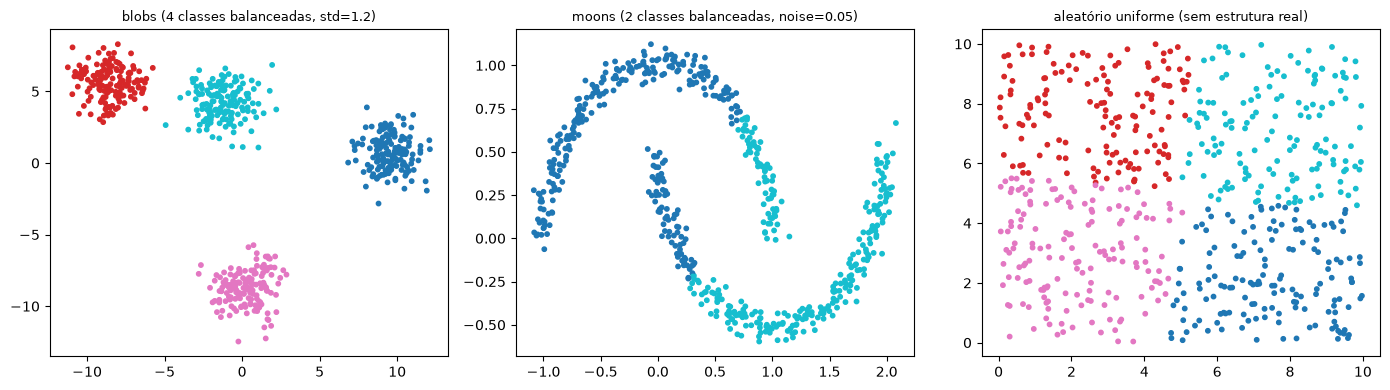

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (nome, (Xc, yc)) in zip(axes, configuracoes.items()):
    lab_exemplo = KMeans(n_clusters=4 if 'blobs' in nome or 'aleat' in nome else 2,
                          n_init=10, random_state=0).fit_predict(Xc)
    ax.scatter(Xc[:, 0], Xc[:, 1], c=lab_exemplo, cmap='tab10', s=10)
    ax.set_title(nome, fontsize=9)
plt.tight_layout(); plt.show()

**Resposta:** Testei 3 configurações de dados sintéticos 2D com N=600 (>= 500 exigido), variando k de 2 a 7 e, para cada combinação (configuração, k), repetindo o K-means com 3 sementes de centroides iniciais diferentes (seeds 0, 1 e 2, com `n_init=1` para isolar o efeito da inicialização).

**1. `make_blobs`, 4 classes balanceadas, `cluster_std=1.2`** (clusters globulares bem definidos): o K-means **acerta perfeitamente em k=4** — ARI médio = **1.000** e inércia idêntica nas 3 sementes (desvio 0.000), ou seja, as 3 inicializações convergem sempre para a mesma partição correta. Em k=2 ou k=3 (abaixo do real), o ARI cai para 0.495 e 0.713 — o algoritmo funde grupos reais. Em k>4 (5, 6, 7) o ARI também cai (0.912 → 0.762) e a variabilidade entre sementes aparece (inércia com desvio > 0) porque agora o K-means precisa dividir um cluster real em dois, e qual divisão "vence" depende da inicialização. **Acerto claro quando k bate com o k real e os clusters são convexos/separados.**

**2. `make_moons`, 2 classes balanceadas, `noise=0.05`** (duas meias-luas entrelaçadas, não convexas): mesmo no k correto (k=2), o ARI é de apenas **0.241** — bem abaixo do acaso razoável — porque o K-means só sabe desenhar fronteiras lineares (via centroides), e uma meia-lua não é um blob esférico: o centróide de cada lua fica "no meio do nada", cortando cada meia-lua ao meio em vez de separar as duas. Nenhum k testado (2 a 7) melhora isso de forma relevante (ARI oscila entre 0.241 e 0.328, nunca ultrapassando ~0.33) — a silhueta, aliás, tampouco aponta k=2 como melhor (sobe de 0.488 em k=2 para 0.526 em k=7). **Erro estrutural: a geometria do K-means (centroides esféricos) é incompatível com a geometria dos dados (formas não convexas).**

**3. Ruído uniforme (sem estrutura de grupo real)**, servindo de controle negativo: por construção não há "k correto"; ainda assim o K-means sempre particiona os dados em k grupos arbitrários, com silhueta entre 0.353 (k=2) e 0.402 (k=4) — numa faixa parecida com a do teste de ruído do handout (L5, acima: 0.359–0.400). **Isso confirma, de novo, que uma silhueta "razoável" sozinha não comprova estrutura real** — aqui sabemos que não há nenhuma, mas o número por si não denunciaria isso.

**Conclusão dos 3 experimentos:** o K-means funciona bem quando (a) o k escolhido coincide com o número real de grupos e (b) os grupos são aproximadamente esféricos/convexos e separados (caso `blobs`). Ele falha sistematicamente quando os grupos têm formato não convexo (caso `moons`), independentemente do k testado, e produz partições "plausíveis" mas sem significado quando não há estrutura real (caso ruído uniforme) — nos três casos, a inicialização (3 seeds) importa mais quando a solução é ambígua (k errado ou geometria incompatível) e importa menos quando a estrutura é forte e inequívoca (blobs no k certo, onde a inércia teve desvio 0.000 entre sementes).

4. Pesquise sobre inicialização **K-Means++**.

**Resposta:** O **K-means++** (Arthur & Vassilvitskii, 2007) é um método de inicialização inteligente dos centroides, criado para resolver exatamente o problema que o K-means clássico tem com inicializações aleatórias: ótimos locais ruins e alta variabilidade de resultado entre execuções (o mesmo problema reproduzido no L2 do handout acima, onde inicialização puramente aleatória falhou em ~1/3 ou mais das tentativas). Em vez de sortear os k centroides iniciais todos de uma vez e uniformemente ao acaso entre os pontos, o k-means++ escolhe o primeiro centróide ao acaso e, a cada passo seguinte, escolhe o próximo centróide entre os pontos restantes com probabilidade **proporcional ao quadrado da distância** até o centróide mais próximo já escolhido (`D(x)²`). Isso faz com que pontos distantes dos centros já escolhidos tenham mais chance de serem escolhidos como novo centro — espalhando os centroides iniciais pelas regiões diferentes do espaço de dados, em vez de deixá-los por acaso próximos uns dos outros ou concentrados numa única região densa.

Segundo a [documentação do scikit-learn](https://scikit-learn.org/stable/modules/clustering.html#k-means) (`sklearn.cluster.KMeans`, parâmetro `init='k-means++'`, que é o **padrão** desde versões recentes da biblioteca), essa estratégia tende a produzir centroides iniciais mais distantes entre si, o que acelera a convergência e aumenta a chance de o algoritmo convergir para o ótimo global (ou perto dele) em menos iterações — sem essa melhoria, seria necessário rodar muito mais repetições com `n_init` alto apenas para compensar inicializações ruins. É por isso que, mesmo usando k-means++ (que no L2 acima acertou 50 de 50 sementes testadas), o scikit-learn ainda mantém `n_init=10` por padrão: k-means++ reduz drasticamente, mas não elimina por garantia matemática, a chance de cair num ótimo local abaixo do ideal.

## Conclusões

- **Exercício 1 (Iris, K-Means vs. rótulos reais):** padronizando as 4 features e usando k=3, o ARI com a espécie real foi **0.620** (silhueta 0.460). A espécie setosa é separada com 100% de acerto; o erro se concentra todo na fronteira entre versicolor e virginica, que se sobrepõem no espaço de features.
- **Exercício 2 (variar k no Iris):** tanto o cotovelo da WCSS quanto a silhueta (máxima em k=2, 0.5818, contra 0.4599 em k=3) apontariam, sem viés de conhecimento prévio, para k=2 — e não para o k=3 real. Isso replica, no Iris, o mesmo fenômeno visto no handout com os pinguins (L4): quando duas categorias reais se sobrepõem geometricamente, os índices internos preferem fundi-las.
- **Exercício 3 (dados sintéticos, 3 configurações × k=2..7 × 3 seeds):** o K-means acerta perfeitamente (ARI=1.000, variância zero entre seeds) quando os grupos são esféricos, separados e k é o correto (`make_blobs`, k=4); falha estruturalmente em grupos não convexos independente do k (`make_moons`, ARI ≤ 0.33 em todos os k testados); e, sobre ruído uniforme sem estrutura real, ainda produz partições com silhueta "razoável" (0.35–0.40) que não significam nada — reforçando a lição do L5 do handout.
- **Exercício 4 (k-means++):** a inicialização k-means++ escolhe centros sucessivos com probabilidade proporcional a D(x)², espalhando-os pelo espaço de dados; isso reduz drasticamente (mas não elimina) o risco de ótimos locais ruins visto com inicialização puramente aleatória, e é por isso que o scikit-learn a usa como padrão mesmo mantendo `n_init=10`.
- **Conexão com o handout opcional:** os quatro exercícios reforçam, com um dataset real (Iris) e sintéticos controlados, exatamente os mesmos alertas vistos no handout `handout-clustering-kmeans.html` — inicialização importa, escala importa, índices internos podem discordar da verdade categórica, e a geometria esférica do K-means tem limites claros.

# Adicional

[![](https://img.youtube.com/vi/njRYKzRKBPY/maxresdefault.jpg)](https://youtu.be/njRYKzRKBPY)

YouTube: [Algoritmo k-means (k-médias)](https://youtu.be/njRYKzRKBPY)